# Exploratory Data Analysis (EDA): Predict Students' Dropout and Academic Success

## 1. Pendahuluan

Exploratory Data Analysis (EDA) merupakan tahap awal dalam analisis data yang bertujuan untuk memahami karakteristik, kualitas, distribusi, serta pola hubungan antarvariabel dalam suatu dataset.

Pada analisis ini, dataset yang digunakan adalah **Predict Students' Dropout and Academic Success** dari UCI Machine Learning Repository. Dataset ini berisi informasi mahasiswa yang dapat digunakan untuk mengeksplorasi hubungan antara karakteristik mahasiswa, pencapaian akademik, dan status akhir mahasiswa.

Tujuan analisis ini adalah memahami struktur dan kualitas data, mengidentifikasi distribusi status mahasiswa, mengeksplorasi perbedaan karakteristik akademik antarkelompok, serta mengamati hubungan antara beberapa variabel numerik. Analisis dilakukan menggunakan Python dengan bantuan Pandas, Matplotlib, dan Seaborn.

Sumber dataset: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success


In [24]:
!pip install -q ucimlrepo

## 2. Memuat dan Memahami Data

Pada tahap ini, dataset dimuat menggunakan pustaka Python yang sesuai. Pemeriksaan awal dilakukan untuk mengetahui jumlah baris dan kolom, melihat beberapa data teratas, memahami tipe data setiap variabel, serta memeriksa nilai kosong dan baris duplikat.

Statistik deskriptif juga digunakan untuk memperoleh gambaran awal mengenai karakteristik variabel numerik. Hasil pemeriksaan ini menjadi dasar untuk menentukan analisis dan visualisasi berikutnya.

In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Mengambil dataset dari UCI
dataset = fetch_ucirepo(id=697)

# Menggabungkan fitur dan kolom target
X = dataset.data.features
y = dataset.data.targets
df = pd.concat([X, y], axis=1)

# Melihat ukuran dan contoh data
print("Ukuran dataset:", df.shape)
display(df.head())

# Memeriksa struktur dan tipe data
df.info()

# Memeriksa nilai kosong dan duplikat
print("\nNilai kosong:")
print(df.isnull().sum().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

# Statistik deskriptif
display(df.describe().T)


Ukuran dataset: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


### 2.1 Hasil Pemeriksaan Awal

Dataset terdiri dari **4.424 baris dan 37 kolom**, yang mencakup variabel karakteristik mahasiswa, informasi akademik, dan status akhir mahasiswa. Pemeriksaan awal menunjukkan bahwa tidak terdapat nilai kosong maupun baris duplikat identik pada dataset.

Meskipun demikian, hasil pemeriksaan tersebut tidak secara otomatis menjamin bahwa seluruh nilai sudah benar atau bebas dari anomali. Oleh karena itu, karakteristik data tetap perlu dipahami melalui statistik deskriptif dan visualisasi.

## 3. Analisis Distribusi dan Karakteristik Data

Tahap ini bertujuan untuk memahami distribusi status akhir mahasiswa dan mengeksplorasi perbedaan karakteristik di antara kelompok Dropout, Enrolled, dan Graduate. Analisis dilakukan menggunakan tabel ringkasan statistik serta visualisasi agar pola yang terdapat dalam dataset lebih mudah dipahami.

### 3.1 Distribusi Status Akhir Mahasiswa

Variabel `Target` menunjukkan status akhir mahasiswa yang terdiri dari tiga kategori, yaitu Dropout, Enrolled, dan Graduate. Grafik distribusi digunakan untuk membandingkan jumlah mahasiswa pada setiap kategori.

Berdasarkan hasil analisis, kategori Graduate merupakan kelompok terbesar dengan 2.209 mahasiswa (49,93%). Selanjutnya, terdapat 1.421 mahasiswa Dropout (32,12%) dan 794 mahasiswa Enrolled (17,95%).

Distribusi ini menunjukkan bahwa hampir setengah dari seluruh data mahasiswa termasuk dalam kategori Graduate. Sementara itu, kategori Dropout juga mencakup bagian yang cukup besar dari dataset.

,Jumlah,Persentase (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


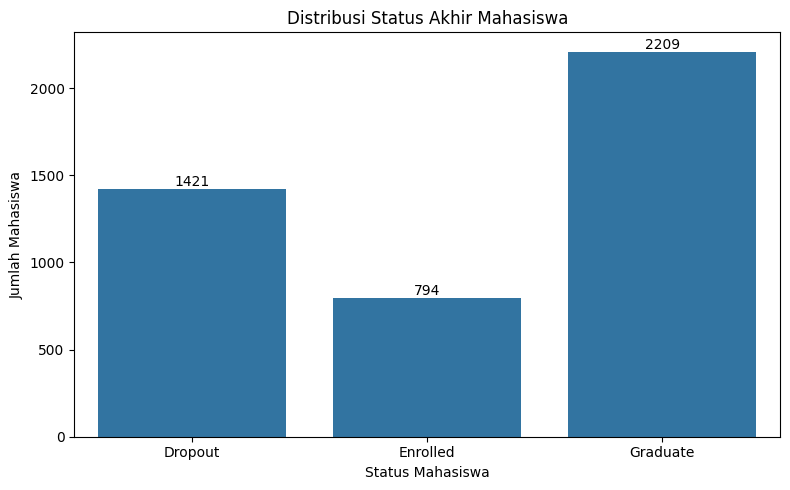

In [26]:

# Menghitung jumlah dan persentase setiap status mahasiswa
target = "Target"

jumlah_status = df[target].value_counts()
persentase_status = (
    df[target].value_counts(normalize=True) * 100
)

ringkasan_status = pd.DataFrame({
    "Jumlah": jumlah_status,
    "Persentase (%)": persentase_status.round(2)
})

display(ringkasan_status)

# Membuat grafik distribusi status mahasiswa
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target,
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Distribusi Status Akhir Mahasiswa")
plt.xlabel("Status Mahasiswa")
plt.ylabel("Jumlah Mahasiswa")

# Menampilkan jumlah pada setiap batang
for bar in ax.patches:
    tinggi = bar.get_height()
    ax.annotate(
        f"{int(tinggi)}",
        (bar.get_x() + bar.get_width() / 2, tinggi),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### 3.2 Analisis Nilai Semester Pertama

Analisis ini membandingkan distribusi nilai semester pertama (`Curricular units 1st sem (grade)`) berdasarkan status akhir mahasiswa. Boxplot digunakan untuk melihat perbedaan median, penyebaran nilai, dan kemungkinan nilai ekstrem pada setiap kelompok.

Hasil ringkasan statistik menunjukkan bahwa kelompok Graduate memiliki rata-rata nilai semester pertama sebesar 12,64, sedangkan kelompok Enrolled sebesar 11,13 dan kelompok Dropout sebesar 7,26.

Perbedaan tersebut memperlihatkan bahwa kelompok Graduate cenderung memiliki nilai semester pertama yang lebih tinggi dibandingkan kelompok Dropout. Namun, temuan ini merupakan pola deskriptif dan tidak membuktikan bahwa nilai semester pertama menjadi satu-satunya penyebab perbedaan status akhir mahasiswa.

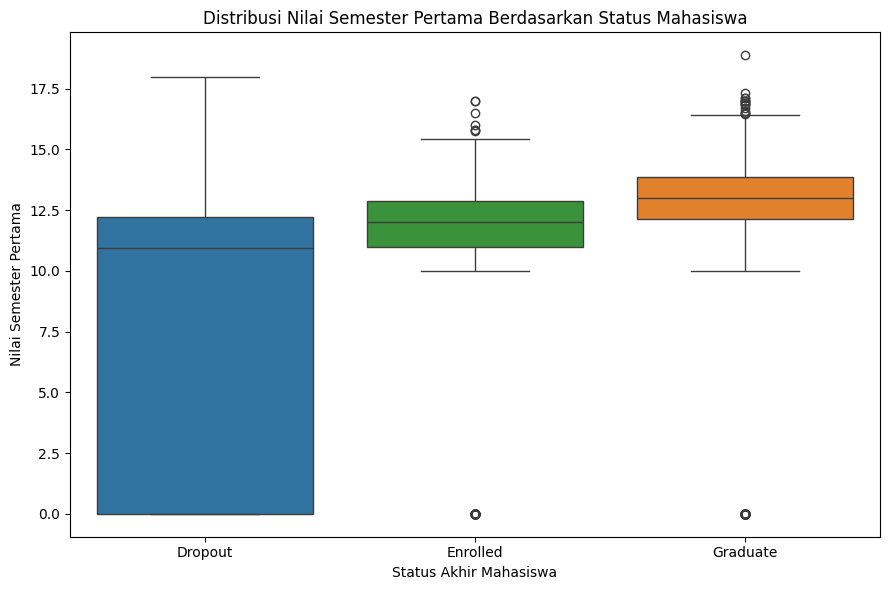

,count,mean,median,min,max
Target,,,,,
Dropout,1421,7.26,10.93,0.0,18.00
Enrolled,794,11.13,12.00,0.0,17.00
Graduate,2209,12.64,13.00,0.0,18.88


In [27]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Distribusi Nilai Semester Pertama Berdasarkan Status Mahasiswa")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Nilai Semester Pertama")
plt.tight_layout()
plt.show()

# Ringkasan nilai per status
ringkasan_nilai = (
    df.groupby("Target")["Curricular units 1st sem (grade)"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(ringkasan_nilai.loc[["Dropout", "Enrolled", "Graduate"]])


### 3.3 Analisis Jumlah Mata Kuliah yang Lulus

Pada bagian ini, variabel `Curricular units 1st sem (approved)` digunakan untuk mengeksplorasi jumlah mata kuliah yang berhasil diselesaikan mahasiswa pada semester pertama. Perbandingan dilakukan berdasarkan status akhir mahasiswa.

Rata-rata jumlah mata kuliah yang lulus pada kelompok Graduate adalah 6,23, diikuti kelompok Enrolled sebesar 4,32 dan kelompok Dropout sebesar 2,55.

Hasil ini menunjukkan adanya perbedaan pencapaian akademik pada semester pertama di antara ketiga kelompok. Kelompok Graduate cenderung memiliki jumlah mata kuliah yang lulus lebih tinggi dibandingkan kelompok Dropout.

In [ ]:

# Membandingkan jumlah mata kuliah yang lulus
kolom = "Curricular units 1st sem (approved)"

ringkasan_lulus = (
    df.groupby("Target")[kolom]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(ringkasan_lulus.loc[["Dropout", "Enrolled", "Graduate"]])

# Membuat boxplot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y=kolom,
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Jumlah Mata Kuliah Semester Pertama yang Lulus")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Jumlah Mata Kuliah Lulus")
plt.tight_layout()
plt.show()


,count,mean,median,min,max
Target,,,,,
Dropout,1421,2.55,2.0,0,21
Enrolled,794,4.32,5.0,0,15
Graduate,2209,6.23,6.0,0,26


### 3.4 Hubungan Nilai Semester Pertama dan Kedua

Hubungan antara nilai semester pertama dan kedua dianalisis menggunakan koefisien korelasi Pearson serta scatter plot. Analisis ini bertujuan untuk mengetahui apakah kedua variabel memiliki kecenderungan hubungan linear.

Hasil perhitungan menunjukkan koefisien korelasi sebesar **0,837**, yang menunjukkan hubungan linear positif yang kuat. Artinya, mahasiswa dengan nilai semester pertama yang lebih tinggi cenderung memiliki nilai semester kedua yang lebih tinggi pula dalam dataset ini.

Korelasi tersebut tidak menunjukkan hubungan sebab-akibat, tetapi memberikan gambaran mengenai pola keterkaitan nilai akademik pada kedua semester.

In [ ]:

kolom_1 = "Curricular units 1st sem (grade)"
kolom_2 = "Curricular units 2nd sem (grade)"

# Menghitung korelasi Pearson
korelasi = df[[kolom_1, kolom_2]].corr().iloc[0, 1]
print(f"Korelasi Pearson: {korelasi:.3f}")

# Scatter plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x=kolom_1,
    y=kolom_2,
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    alpha=0.5
)

plt.title("Hubungan Nilai Semester Pertama dan Kedua")
plt.xlabel("Nilai Semester Pertama")
plt.ylabel("Nilai Semester Kedua")
plt.tight_layout()
plt.show()


### 3.5 Analisis Usia Saat Mendaftar

Analisis usia saat mendaftar (`Age at enrollment`) dilakukan untuk melihat perbedaan karakteristik usia mahasiswa berdasarkan status akhir. Boxplot dan statistik deskriptif digunakan untuk membandingkan distribusi usia pada setiap kelompok.

Rata-rata usia saat mendaftar pada kelompok Dropout adalah 26,07 tahun, sedangkan kelompok Enrolled sebesar 22,37 tahun dan kelompok Graduate sebesar 21,78 tahun.

Dalam dataset ini, kelompok Dropout memiliki rata-rata usia saat mendaftar yang lebih tinggi dibandingkan dua kelompok lainnya. Temuan ini menunjukkan adanya perbedaan distribusi usia, tetapi belum cukup untuk menyimpulkan bahwa usia menyebabkan mahasiswa mengalami dropout.

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Distribusi Usia Masuk Berdasarkan Status Akhir Mahasiswa")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Usia Saat Masuk Kuliah (tahun)")
plt.tight_layout()
plt.show()

ringkasan_usia = df.groupby("Target")["Age at enrollment"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(ringkasan_usia.loc[["Dropout", "Enrolled", "Graduate"]])

In [ ]:

# Menampilkan informasi variabel Gender dari dokumentasi dataset
print(dataset.variables[
    dataset.variables["name"].str.contains("Gender", case=False, na=False)
].to_string(index=False))



### 3.6 Analisis Status Akhir Berdasarkan Gender

Analisis ini membandingkan status akhir mahasiswa berdasarkan variabel `Gender`. Berdasarkan metadata dataset, nilai 0 menunjukkan perempuan dan nilai 1 menunjukkan laki-laki. Tabel silang dan grafik persentase digunakan untuk membandingkan proporsi status akhir pada masing-masing kelompok gender.

Hasil analisis menunjukkan bahwa proporsi Dropout pada kelompok laki-laki adalah 45,05%, sedangkan pada kelompok perempuan sebesar 25,10%. Sebaliknya, proporsi Graduate pada kelompok perempuan sebesar 57,91%, sedangkan pada kelompok laki-laki sebesar 35,22%.

Perbedaan tersebut menggambarkan pola yang terlihat dalam dataset ini. Namun, hasilnya tidak dapat langsung digeneralisasikan kepada seluruh mahasiswa dan tidak membuktikan bahwa gender merupakan penyebab perbedaan status akhir.

In [ ]:
# Menghitung jumlah mahasiswa berdasarkan jenis kelamin dan status
tabel_gender = pd.crosstab(
    df["Gender"],
    df["Target"]
)

display(tabel_gender)

# Menghitung persentase status di setiap kelompok gender
persentase_gender = pd.crosstab(
    df["Gender"],
    df["Target"],
    normalize="index"
) * 100

display(persentase_gender.round(2))

# Membuat grafik
persentase_gender.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.title("Distribusi Status Akhir Mahasiswa Berdasarkan Gender")
plt.xlabel("Gender")
plt.ylabel("Persentase (%)")
plt.legend(title="Status Mahasiswa")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Analisis Korelasi Antarvariabel Numerik

Analisis korelasi digunakan untuk mengeksplorasi kekuatan dan arah hubungan linear antara beberapa variabel numerik yang berkaitan dengan pencapaian akademik dan usia mahasiswa. Visualisasi heatmap membantu menunjukkan hubungan tersebut secara lebih ringkas.

Matriks korelasi yang digunakan mencakup nilai semester pertama dan kedua, jumlah mata kuliah yang lulus pada kedua semester, serta usia saat mendaftar.

Hasil analisis menunjukkan bahwa korelasi tertinggi di antara pasangan variabel yang diperiksa terdapat pada jumlah mata kuliah yang lulus pada semester pertama dan kedua, dengan nilai korelasi sebesar 0,904. Hubungan ini menunjukkan bahwa mahasiswa yang lulus lebih banyak mata kuliah pada semester pertama cenderung juga lulus lebih banyak mata kuliah pada semester kedua.

Sementara itu, korelasi antara usia saat mendaftar dan variabel akademik yang dianalisis cenderung negatif dan relatif lemah. Perlu diperhatikan bahwa korelasi hanya menggambarkan hubungan linear dan tidak menunjukkan hubungan sebab-akibat. Analisis ini juga terbatas pada variabel yang dipilih, sehingga belum mewakili seluruh hubungan dalam dataset.

In [ ]:

# Memilih variabel yang akan dianalisis
kolom_akademik = [
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Age at enrollment"
]

# Menghitung matriks korelasi
matriks_korelasi = df[kolom_akademik].corr()

# 1. Menampilkan tabel angka korelasi
print("Tabel Korelasi Antarvariabel:")
display(matriks_korelasi.round(3))

# 2. Menampilkan heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Korelasi Variabel Akademik dan Usia")
plt.tight_layout()
plt.show()


## 5. Kesimpulan

Berdasarkan Exploratory Data Analysis (EDA) terhadap 4.424 data mahasiswa, kelompok Graduate merupakan kelompok terbesar dengan persentase 49,93%, diikuti Dropout sebesar 32,12% dan Enrolled sebesar 17,95%. Pemeriksaan awal menunjukkan tidak terdapat nilai kosong maupun baris duplikat identik pada dataset.

Hasil analisis menunjukkan bahwa kelompok Graduate memiliki rata-rata nilai semester pertama dan jumlah mata kuliah yang lulus lebih tinggi dibandingkan kelompok Dropout. Korelasi antara nilai semester pertama dan kedua sebesar 0,837, sedangkan korelasi jumlah mata kuliah yang lulus pada kedua semester mencapai 0,904. Kelompok Dropout juga memiliki rata-rata usia saat mendaftar yang lebih tinggi. Berdasarkan gender, proporsi Dropout pada kelompok laki-laki lebih tinggi dibandingkan kelompok perempuan dalam dataset ini.

Secara keseluruhan, EDA ini memberikan gambaran mengenai distribusi status akhir mahasiswa serta pola hubungan antara karakteristik akademik, usia, dan gender. Temuan yang diperoleh bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat. Analisis ini juga belum mencakup seluruh variabel dalam dataset. Dengan demikian, hasil EDA dapat digunakan sebagai dasar untuk memahami data lebih lanjut tanpa harus membangun model Machine Learning pada tahap ini.